# Diagnóstico de marca empleadora — Bayer vs. peers
## Sentiment analysis (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de Bayer como empleador, a partir de lo que dicen sus empleados en Glassdoor, y compararlos con los de sus competidores directos.

**Peers elegidos:** Novartis, Pfizer y AstraZeneca. Son importantes empresas farmacéuticas multinacionales.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA: rating, recomendación, empleados actuales vs. antiguos |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic |
| 4 | Comparación con peers: peso de cada topic y balance neto |
| 5 | Empleados actuales vs. antiguos |
| 6 | Conclusiones y recomendaciones para RRHH |




In [1]:
# En Colab: transformers ya viene instalado; BERTopic no.
!pip install -q bertopic sentence-transformers

---
## 0. Carga y preparación

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


La primera vez que se ejecuta la celda de abajo cargamos el archivo glassdoor_reviews_hr.parquet. Una vez cargado y seleccionadas las reseñas de 4 empresas, guardamos ese df como df_trabajo.csv y será el que carguemos siempre. De esta manera evitaremos aleatoriedad al elegir reseñas cada vez que se carga el .parquet

In [3]:
# Cargamos el archivo que tenemos en local
from google.colab import files
uploaded = files.upload()


Saving df_trabajo.csv to df_trabajo (2).csv


El siguientes bloque de código se ejecutó sólo la primera vez para seleccionar del glassdoor_reviews_hr.parquet las 4 empresas que se iban a estudiar y las 1000 reseñas por cada empresa.

In [4]:
# # Elección de empresa objetivo y peers
# target = 'Bayer'
# peers = ['Novartis', 'AstraZeneca', 'Pfizer']
# firms = [target] + peers

# # Tope de reseñas por empresa
# max_reseñas = 1000
# SEED = 42


# try:
#     df_raw = pd.read_parquet('glassdoor_reviews_hr.parquet', filters=[('firm', 'in', firms)])
#     # Para garantizar que siempre se carge el .parquet en el mismo orden
#     # df_raw = df_raw.reset_index(drop=True)
#     # df_raw["row_id"] = df_raw.index
#     # df_raw = df_raw.sort_values(["firm", "row_id"]).reset_index(drop=True)

#     print('Reseñas disponibles por empresa:')
#     print(df_raw['firm'].value_counts())

#     # Toma el máximo de reseñas aleatorias por empresa (firm) de df_raw, y las une todas en un solo DataFrame df, con índice reiniciado.
#     df = pd.concat([g.sample(n=min(max_reseñas, len(g)), random_state=SEED)
#                     for _, g in df_raw.groupby('firm')], ignore_index=True)
#     print(f'\nMuestra de trabajo: {len(df):,} reseñas')
# except Exception as e:
#     print(f"Error al cargar el dataset: {e}")
#     print("Por favor, asegúrate de que el archivo 'glassdoor_reviews_hr.parquet' se ha subido correctamente y no está vacío o corrupto.")

Con la celda de abajo creamos la primera vez el .csv que se va a utilizar. De esta manera evitamos aleatoriedad en los resultados al cargar cada vez el archivo .parquet y seleccionar las reseñas.

In [5]:
# df = df.copy()   # tu dataframe final ya filtrado
# df.to_csv("df_trabajo.csv", index=False)


In [6]:
df = pd.read_csv("df_trabajo.csv")

In [7]:
df.columns

Index(['firm', 'date_review', 'current', 'overall_rating', 'recommend', 'pros',
       'cons'],
      dtype='object')

In [8]:
df_bayer=df[df["firm"]=="Bayer"]
df_bayer.head()

,firm,date_review,current,overall_rating,recommend,pros,cons
1000,Bayer,2019-12-17,"Former Employee, more than 3 years",3.0,v,- Great environment;\n- Leaders concerned with...,-Company now focused on shareholder value... n...
1001,Bayer,2023-02-20,"Current Employee, more than 1 year",4.0,v,"Excellent talent all around, specially in Medi...",Management positions outdated (more than needed)
1002,Bayer,2023-02-15,Former Employee,5.0,o,Competitive pay; great culture; supportive team,None that I can think of
1003,Bayer,2021-11-25,Current Employee,5.0,o,"Employee development is a big focus, employee ...",only if there is a position of interest within...
1004,Bayer,2020-09-20,"Former Employee, more than 3 years",4.0,v,"You can grown as a profissional there, lots of...",They have too much terceirize employees to don...


In [9]:
df_astra=df[df["firm"]=="AstraZeneca"]
df_astra.head()

,firm,date_review,current,overall_rating,recommend,pros,cons
0,AstraZeneca,2020-09-12,"Former Employee, more than 3 years",1.0,x,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m..."
1,AstraZeneca,2021-08-02,"Former Employee, more than 8 years",3.0,x,"development\nsome pay and benefits good, share...",not strong in terms of marketing campaigns for...
2,AstraZeneca,2022-02-16,"Former Employee, more than 5 years",1.0,x,None the worst to work for,Micro management \r\nManagers were not sales p...
3,AstraZeneca,2021-01-17,Former Employee,4.0,o,Good company. Good people. Good benefits,Same mid level management issues every large c...
4,AstraZeneca,2019-09-08,"Current Employee, more than 10 years",4.0,v,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Har...


In [10]:
df_pfizer=df[df["firm"]=="Pfizer"]
df_pfizer.head()

,firm,date_review,current,overall_rating,recommend,pros,cons
3000,Pfizer,2022-03-04,Current Employee,5.0,o,Flexible and understanding and very nice peopl...,I dont really have any honestly
3001,Pfizer,2018-10-03,"Current Employee, more than 3 years",4.0,v,Pfizer has treated me well. I’ve received good...,"Very large company, meaning it can be difficul..."
3002,Pfizer,2019-06-28,Current Employee,2.0,o,Healthcare free car park canteen,"Training, lack of effort to retain staff."
3003,Pfizer,2019-05-31,"Current Employee, more than 5 years",5.0,v,Pay and benefits. Safe and clean working envir...,The site is closing at the end of 2020
3004,Pfizer,2021-12-20,"Current Employee, more than 5 years",4.0,v,"Location, people, diversity of opportunity, gl...","Low pay, bureaucracy, stagnant growth opportunity"


In [11]:
df_novartis=df[df["firm"]=="Novartis"]
df_novartis.head()

,firm,date_review,current,overall_rating,recommend,pros,cons
2000,Novartis,2021-09-03,"Current Employee, more than 5 years",4.0,v,"Flexible, good culture, no work pressure","Slow growth, limited learning in terms of tech..."
2001,Novartis,2022-03-17,Current Employee,5.0,v,"Work Life balance and stability, decent scienc...",Depends of group some areas will have heavy wo...
2002,Novartis,2022-02-05,Former Employee,5.0,o,great company to work for,nothing negative to report about novartis
2003,Novartis,2020-10-06,Current Employee,4.0,v,"Good benefits, people orientated, good career ...","Weighty processes, slow on the uptake of initi..."
2004,Novartis,2021-08-18,Former Employee,5.0,v,Positive environment and great people to work ...,Nothing except the competition over there


---
## 1. EDA

### Limpieza de datos

En primero lugar miramos los tipos de datos y el descriptivo de las variables

In [12]:
df.dtypes

,0
firm,object
date_review,object
current,object
overall_rating,float64
recommend,object
pros,object
cons,object


In [13]:
# Tipo de dato en cada variable
for i in df.columns:
    print(df[i].apply(type).value_counts())


firm
<class 'str'>    4000
Name: count, dtype: int64
date_review
<class 'str'>    4000
Name: count, dtype: int64
current
<class 'str'>    4000
Name: count, dtype: int64
overall_rating
<class 'float'>    4000
Name: count, dtype: int64
recommend
<class 'str'>    4000
Name: count, dtype: int64
pros
<class 'str'>    4000
Name: count, dtype: int64
cons
<class 'str'>    4000
Name: count, dtype: int64


Todas las variables tienen el tipo de dato adecuado. overall_rating aparece como float y lo vamos a cambiar a int, aunque no sería estrictamente necesario

In [14]:
#Compruebo si hay algún nan en alguna columna
for i in df.columns:
    print(df[i].isna().sum())

0
0
0
0
0
0
0


No hay nan. Cambio overall_rating a int

In [15]:
df['overall_rating'] = df['overall_rating'].astype(int)


In [16]:
# Descriptivo
df.describe(include='all')

,firm,date_review,current,overall_rating,recommend,pros,cons
count,4000,4000,4000,4000.000000,4000,4000,4000
unique,4,1444,14,NaN,3,3962,3968
top,AstraZeneca,2021-03-02,Current Employee,NaN,v,Great company to work for,None that I can think of
freq,1000,13,1094,NaN,2269,8,11
mean,NaN,NaN,NaN,4.042750,NaN,NaN,NaN
std,NaN,NaN,NaN,1.043885,NaN,NaN,NaN
min,NaN,NaN,NaN,1.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,4.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,4.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,5.000000,NaN,NaN,NaN


Convierto date_review en día, mes, año

In [17]:
# Dividir fecha en día, mes, año
df['date_review'] = pd.to_datetime(df['date_review'])
df['year'] = df['date_review'].dt.year
df['month'] = df['date_review'].dt.month
df['day'] = df['date_review'].dt.day

df.head()

,firm,date_review,current,overall_rating,recommend,pros,cons,year,month,day
0,AstraZeneca,2020-09-12,"Former Employee, more than 3 years",1,x,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12
1,AstraZeneca,2021-08-02,"Former Employee, more than 8 years",3,x,"development\nsome pay and benefits good, share...",not strong in terms of marketing campaigns for...,2021,8,2
2,AstraZeneca,2022-02-16,"Former Employee, more than 5 years",1,x,None the worst to work for,Micro management \r\nManagers were not sales p...,2022,2,16
3,AstraZeneca,2021-01-17,Former Employee,4,o,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17
4,AstraZeneca,2019-09-08,"Current Employee, more than 10 years",4,v,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Har...,2019,9,8


#### Compruebo qué contienen las variables current y recommend

In [18]:
df['current'].unique()

array(['Former Employee, more than 3 years',
       'Former Employee, more than 8 years',
       'Former Employee, more than 5 years', 'Former Employee',
       'Current Employee, more than 10 years', 'Current Employee',
       'Current Employee, more than 3 years',
       'Former Employee, more than 1 year',
       'Current Employee, more than 5 years',
       'Current Employee, more than 1 year',
       'Current Employee, less than 1 year',
       'Current Employee, more than 8 years',
       'Former Employee, more than 10 years',
       'Former Employee, less than 1 year'], dtype=object)

La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables: employee y tenure.

In [19]:
def employee(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'current'
    if s.startswith('former'):
        return 'former'
    return 'unknown'

def tenure(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

# Genero las columnas employee y tenure y elimino current
df['employee'] = df['current'].map(employee)
df['tenure'] = df['current'].map(tenure)
df=df.drop(columns=['current'])
df.head()


#print(df['employee'].value_counts())
df.head()
#df[['firm', 'date_review', 'employee', 'tenure', 'overall_rating', 'recommend', 'pros', 'cons']].head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure
0,AstraZeneca,2020-09-12,1,x,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y
1,AstraZeneca,2021-08-02,3,x,"development\nsome pay and benefits good, share...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y
2,AstraZeneca,2022-02-16,1,x,None the worst to work for,Micro management \r\nManagers were not sales p...,2022,2,16,former,more than 5y
3,AstraZeneca,2021-01-17,4,o,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d
4,AstraZeneca,2019-09-08,4,v,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Har...,2019,9,8,current,more than 10y


Compruebo los valores únicos de recommend

In [20]:
df['recommend'].unique()

array(['x', 'o', 'v'], dtype=object)

Modifico la columna `recommend` (v = sí, o = sin opinión, x = no)

In [21]:
df['recommend'] = df['recommend'].map({'v': 'Yes', 'o': 'Neutral', 'x': 'No'})
df.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y
1,AstraZeneca,2021-08-02,3,No,"development\nsome pay and benefits good, share...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management \r\nManagers were not sales p...,2022,2,16,former,more than 5y
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Har...,2019,9,8,current,more than 10y


Elimino saltos de línea, espacios,... en pros y cons. No hago limpieza más "agresiva" porque BERTopic utiliza el contexto

In [22]:
# Eliminar saltos de línea o espacios en pros y cons
for col in ['pros', 'cons']:
    df[col] = df[col].str.replace(r'\s+', ' ', regex=True).str.strip()

### Análisis de variables

- Para cada firma muestra el numero de reseñas, rating medio % que recomiendan, % de empleados actuales
- Compara rating dado por empleados actuales vs empleados antiguos
- Evolucion del rating
- ...

In [23]:
summary = (
    df.groupby("firm")
      .agg(
          n_reviews = ("firm", "count"),
          rating_mean = ("overall_rating", "mean"),
          pct_recommend = ("recommend", lambda x: (x == "Yes").mean() * 100),
          pct_current = ("employee", lambda x: (x == "current").mean() * 100)
      )
      .reset_index()
)

summary


,firm,n_reviews,rating_mean,pct_recommend,pct_current
0,AstraZeneca,1000,4.066,60.4,69.3
1,Bayer,1000,3.980,54.2,60.5
2,Novartis,1000,4.016,59.8,68.2
3,Pfizer,1000,4.109,52.5,61.8


El promedio de rating es bastante parecido en las cuatro empresas, estando Bayer en cola, aunque la de Pfizer, que está en cabeza, es la que menor porcentaje de recomendación tiene. Dato curioso. Indica que aunque se recomiende menos, la valoración (rating) no es tan negativa

Vamos a ver porcentajes de rating por cada empresa, para comprobar la conclusión anterior

In [24]:
rating_pct = (
    df.groupby("firm")["overall_rating"]
      .value_counts(normalize=True)   # proporción
      .mul(100)                       # a porcentaje
      .rename("pct")
      .reset_index()
)

rating_pct_pivot = (
    rating_pct.pivot(index="firm", columns="overall_rating", values="pct")
              .fillna(0)
)

rating_pct_pivot




overall_rating,1,2,3,4,5
firm,,,,,
AstraZeneca,4.2,4.7,13.2,36.1,41.8
Bayer,3.6,5.9,16.9,36.1,37.5
Novartis,3.8,5.1,16.1,35.7,39.3
Pfizer,3.2,4.5,14.1,34.6,43.6


Efectivamente, Pfizer tienen el menor porcentaje (3.2%) de valoración mínima (1)

Vemos la valoración de los antiguos empleados frente a los actuales

In [25]:
rating_firm_employee = (
    df.groupby(["firm", "employee"])["overall_rating"]
      .agg(["count", "mean"])
      .rename(columns={"count": "n_reviews", "mean": "rating_mean"})
      .reset_index()
)

rating_firm_employee


,firm,employee,n_reviews,rating_mean
0,AstraZeneca,current,693,4.212121
1,AstraZeneca,former,307,3.736156
2,Bayer,current,605,4.024793
3,Bayer,former,395,3.911392
4,Novartis,current,682,4.082111
5,Novartis,former,318,3.874214
6,Pfizer,current,618,4.171521
7,Pfizer,former,382,4.007853


Parece haber una mejor valoración de los empleados actuales que de los antiguos en las cuatro empresas

### Evolución del rating con el tiempo

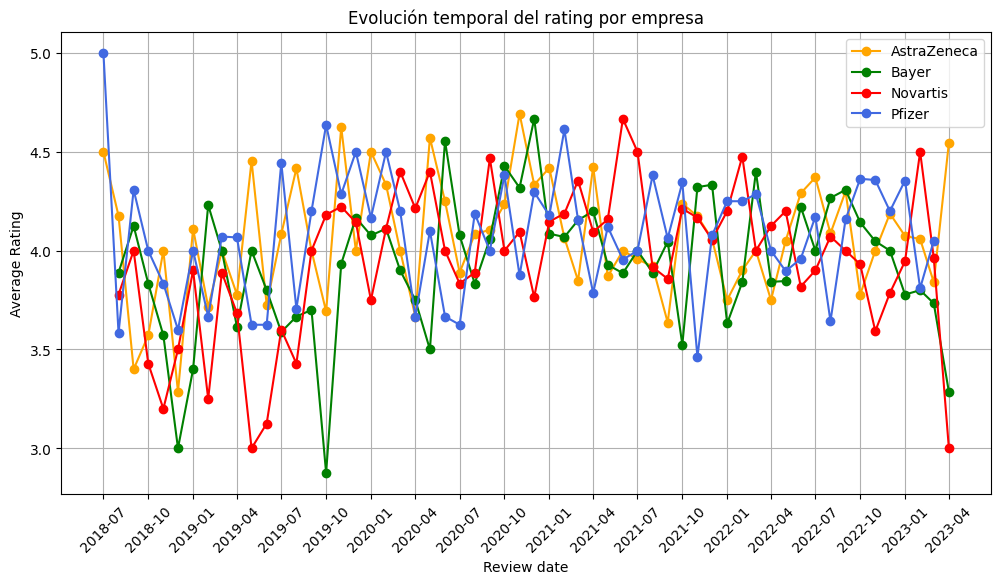

In [26]:
import matplotlib.dates as mdates


# Agrupar por empresa, año y mes
rating_time = (
    df.groupby(["firm", "year", "month"])["overall_rating"]
      .mean()
      .reset_index()
      .sort_values(["firm", "year", "month"])
)

# Crear columna fecha (primer día del mes)
rating_time["date"] = pd.to_datetime(
    rating_time["year"].astype(str) + "-" +
    rating_time["month"].astype(str) + "-01"
)

# Gráfica
plt.figure(figsize=(12,6))

colors = {
"Bayer": "green",
"AstraZeneca": "orange",
"Novartis": "red",
"Pfizer": "royalblue"
}

for firm in rating_time["firm"].unique():
    subset = rating_time[rating_time["firm"] == firm]
    plt.plot(subset["date"], subset["overall_rating"], marker="o", label=firm, color=colors[firm]
)

plt.title("Evolución temporal del rating por empresa")
plt.xlabel("Review date")
plt.ylabel("Average Rating")
plt.legend()
plt.grid(True)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))  # cada 3 meses
plt.xticks(rotation=45)

plt.show()


Aunque hay fluctuaciones, no se observan grandes diferencias entre las cuatro empresas con el tiempo. Sí parece haber una ligera subida en todas a partir de 2020, que se mantiene en el tiempo

---
## 2. Sentimiento en pros y cons (control de calidad)

Los pros y cons  ya nos darían un sentimiento, pero haremos un control de calidad para verificar que el sentimiento predominande en pros es el positivo y en cons es en negativo.

Para ello utilizamos `distilbert-base-uncased-finetuned-sst-2-english`. Es binario (POSITIVE / NEGATIVE, sin clase neutral) y trabaja con un máximo de 512 tokens, por lo que se usa `truncation=True`.


In [27]:
#'distilbert-base-uncased-finetuned-sst-2-english', ha tardado 37 min para 47000 reseñas

In [28]:
from transformers import pipeline

# Cargar el modelo
sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True
)

# Aplicar a pros y cons por separado

df["sentiment_pros"] = df["pros"].apply(lambda x: sentiment_model(x)[0]["label"])
df["sentiment_cons"] = df["cons"].apply(lambda x: sentiment_model(x)[0]["label"])

# Resultados en pct
pct_pros_positive = (df["sentiment_pros"] == "POSITIVE").mean() * 100
pct_cons_negative = (df["sentiment_cons"] == "NEGATIVE").mean() * 100

print(f"% de pros POSITIVE: {pct_pros_positive:.2f}%")
print(f"% de cons NEGATIVE: {pct_cons_negative:.2f}%")



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

% de pros POSITIVE: 94.85%
% de cons NEGATIVE: 79.90%


Los porcentajes de acierto en pros y cons son bastante altos (94.85% y 79.90% respectivamente)

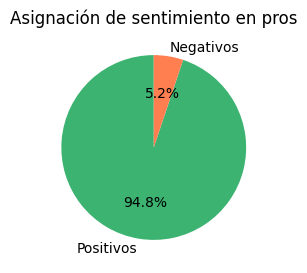

In [29]:
pct_pros_neg = 100 - pct_pros_positive

plt.figure(figsize=(3, 3))

plt.pie(
    [pct_pros_positive, pct_pros_neg ],
    labels=["Positivos", "Negativos"],
    autopct="%1.1f%%",
    colors=["mediumseagreen", "coral"],
    startangle=90
    )

plt.title("Asignación de sentimiento en pros")

plt.show()

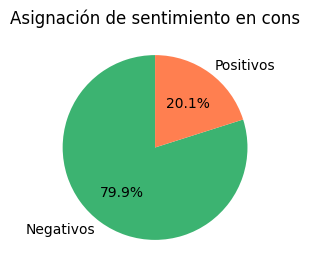

In [30]:
pct_cons_positive = 100 - pct_cons_negative

plt.figure(figsize=(3, 3))

plt.pie(
    [pct_cons_negative, pct_cons_positive ],
    labels=["Negativos", "Positivos"],
    autopct="%1.1f%%",
    colors=["mediumseagreen", "coral"],
    startangle=90
    )

plt.title("Asignación de sentimiento en cons")

plt.show()

#### Análisis de discordantes

In [31]:
# Pros que salen NEGATIVE
discordant_pros = df[df["sentiment_pros"] == "NEGATIVE"][["pros"]].head(10)

discordant_pros

,pros
0,Company starting time good .. nothing present
2,None the worst to work for
16,High retention during poor economic times unle...
26,Room to grow in advance your career
37,Flat structure Exposure to different markets e...
54,Room for growth and development
70,Sadly none to speak of
99,Company car and volunteer time off.
107,Bullying from management. Even compliance was ...
162,"Great team, a lot of services to grow in, no m..."


In [32]:
# Cons que salen POSITIVE
discordant_cons = df[df["sentiment_cons"] == "POSITIVE"][["cons"]].head(10)
discordant_cons

,cons
6,Streamlininig of systems and process required
8,"Very few, and I would say they depend on your ..."
10,"always running, little time to rest."
21,I love the company & great place to work
23,Works Loads can be interesting.
43,Salary based off years of experience and loyal...
45,Flexibility across all job functions
46,Culture: The culture is one in which a lot of ...
53,"Lack of communication, but it is improving."
54,they are still unclear about whether or not th...


---
## 3. Topic modeling


## **NOTA IMPORTANTE!!**

### Este código se creó y se ejecutó en Google Colab. Aunque hemos fijado la semilla de aleatoriedad en el modelo, en función de cómo se ejecute Google Colab se obtienen diferentes resultados. En una sesión, ejecutada varias veces, se obtiene lo mismo, pero al cambiar de sesión, pueden cambiar los resultados.

### Aunque las conclusiones finales deberían ser similares, los valores absolutos no tienen por qué serlo. Todos los comentarios se han hecho en base a una ejecución. Si los comentarios no coinciden con los resultados de tablas y figuras es porque la ejecución se ha realizado de distinta manera. No he conseguido controlar la aleatoriedad de BerTopic con Google Colab. DistilBERT, sin embargo, siempre mostró el mismo resultado.

Utlizamos el modelo BERTopic para el análisis de topics. - Se utiliza un modelo para todas las empresas (uno para pros y otro para cons) para que coincidan los topics y poder comparar entre empresas

Además de eliminar stopwords, se van a eliminar los nombres de las empresas si aparecen en las columnas pros y cons para que no afecten a la hora de clasificar topics.

Revisamos cuántas veces aparece el nombre de la empresa o sus variantes en pros y cons

In [33]:
empresas = ["bayer", "astrazeneca", "pfizer", "novartis", "az", "pf", "nov"]

import re

conteos_pros = {
    e: df["pros"].str.lower().apply(lambda x: len(re.findall(fr"\b{e}\b", x))).sum()
    for e in empresas
}

conteos_cons = {
    e: df["cons"].str.lower().apply(lambda x: len(re.findall(fr"\b{e}\b", x))).sum()
    for e in empresas
}

print(conteos_pros)
print(conteos_cons)


{'bayer': np.int64(39), 'astrazeneca': np.int64(7), 'pfizer': np.int64(42), 'novartis': np.int64(37), 'az': np.int64(26), 'pf': np.int64(0), 'nov': np.int64(0)}
{'bayer': np.int64(48), 'astrazeneca': np.int64(16), 'pfizer': np.int64(42), 'novartis': np.int64(30), 'az': np.int64(14), 'pf': np.int64(0), 'nov': np.int64(0)}


Eliminamos en los textos de pros y cons el nombre de la empresa.

In [34]:
# Poner todo en minúsculas
df["pros_clean"] = df["pros"].str.lower()
df["cons_clean"] = df["cons"].str.lower()

# Eliminar nombre de empresa
for e in empresas:
    df["pros_clean"] = df["pros_clean"].str.replace(e, "", regex=False)
    df["cons_clean"] = df["cons_clean"].str.replace(e, "", regex=False)


# Limpieza de espacios
df["pros_clean"] = df["pros_clean"].str.replace(r"\s+", " ", regex=True).str.strip()
df["cons_clean"] = df["cons_clean"].str.replace(r"\s+", " ", regex=True).str.strip()

# Convertimos cadenas vacías o solo espacios a NaN
df["pros_clean"] = df["pros_clean"].replace(r"^\s*$", np.nan, regex=True)
df["cons_clean"] = df["cons_clean"].replace(r"^\s*$", np.nan, regex=True)

# Eliminación de algún NAN si se ha generado al eliminar el nombre de la empresa
df_clean = df.dropna(subset=["pros_clean", "cons_clean"])


text_pros = df_clean["pros_clean"].tolist()
text_cons = df_clean["cons_clean"].tolist()



In [35]:
df_clean.shape

(4000, 15)

Parece ser que ninguna celda en pros y cons contenía sólo el nombre de la empresa

In [36]:
df_clean["firm"].value_counts()


,count
firm,
AstraZeneca,1000
Bayer,1000
Novartis,1000
Pfizer,1000


In [37]:
!pip install -q bertopic sentence-transformers


from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer

#Eliminar stop words
vectorizer_model = CountVectorizer(stop_words="english")

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Este es el modelo UMAP por defecto en BERTopic. Lo pongo de referencia
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42  # Fijo la semilla de aleatoriedad. No es fija por defecto
)

# Este es el modelo HDBSCAN por defecto en BERTopic. Lo pongo de referencia
hdbscan_model = HDBSCAN(
    min_cluster_size=10,
    min_samples=10,
    cluster_selection_method='eom',
    prediction_data=True
)


# Modelo para pros
topic_model_pros = BERTopic(
    vectorizer_model=vectorizer_model,
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    language="english",
    verbose=True
)

#Topic asignado a cada reseña
topics_pros, probs_pros = topic_model_pros.fit_transform(text_pros)

# Modelo para cons
topic_model_cons = BERTopic(
    vectorizer_model=vectorizer_model,
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    language="english",
    verbose=True
)

#Topic asignado a cada reseña
topics_cons, probs_cons = topic_model_cons.fit_transform(text_cons)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-10 19:01:57,305 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:02:42,374 - BERTopic - Embedding - Completed ✓
2026-10-10 19:02:42,375 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-10 19:03:31,077 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:03:31,079 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-10 19:03:31,262 - BERTopic - Cluster - Completed ✓
2026-10-10 19:03:31,270 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:03:31,400 - BERTopic - Representation - Completed ✓
2026-10-10 19:03:31,595 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:04:21,204 - BERTopic - Embedding - Completed ✓
2026-10-10 19:04:21,207 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-10 19:05:00,387 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:05:00,389 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-10 19:05:00,555 - BERTopic - Cluster - Completed ✓
2026-10-10 19:05:00,562 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:05:00,673 - BERTopic - Representation - Completed ✓


In [38]:
# Ver los topics y las palabras clave asignadas a cada topic
topics_info_pros=topic_model_pros.get_topic_info()
topics_info_pros # DataFrame resumen de topics


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1287,-1_good_life_salary_balance,"[good, life, salary, balance, benefits, work, ...","[work life balance, growth, good salary, cultu..."
1,0,444,0_culture_great_work_unbossed,"[culture, great, work, unbossed, life, good, b...","[the company culture is not good, good work cu..."
2,1,207,1_place_work_great_location,"[place, work, great, location, nice, learn, go...","[great place to work here, great place to work..."
3,2,109,2_hours_flexible_schedule_working,"[hours, flexible, schedule, working, flex, hap...","[flexible working hours and great salary., fle..."
4,3,101,3_environment_working_friendly_healthy,"[environment, working, friendly, healthy, envi...","[very good environment to work there, good env..."
...,...,...,...,...,...
57,56,11,56_collaborative_automated_collaboration_envir...,"[collaborative, automated, collaboration, envi...","[very collaborative place to work., good worki..."
58,57,11,57_pay_pretty_suck_decent,"[pay, pretty, suck, decent, opinion, rates, th...","[the pay is pretty good, pay is pretty good he..."
59,58,11,58_training_ard_cgmps_proactive,"[training, ard, cgmps, proactive, systematic, ...","[good benefits and very good training., chance..."
60,59,11,59_colleagues_flexible_bossism_afz,"[colleagues, flexible, bossism, afz, bureaucra...","[development of employees, flexible, empathic,..."


In [39]:
topics_info_cons=topic_model_cons.get_topic_info().head(10)
topics_info_cons #DataFrame resumen de topics


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1227,-1_management_work_people_company,"[management, work, people, company, employees,...",[- think twice for your mental health and sani...
1,0,309,0_salary_pay_low_benefits,"[salary, pay, low, benefits, compensation, com...",[poor management low salary compared to indust...
2,1,271,1_career_growth_opportunities_development,"[career, growth, opportunities, development, l...",[there are no growth opportunities for everyon...
3,2,173,2_cons_think_far_don,"[cons, think, far, don, mention, observed, spe...","[there is no cons at, there are no cons at all..."
4,3,115,3_balance_life_work_maintain,"[balance, life, work, maintain, hours, better,...","[work life balance is off, no work/life balanc..."
5,4,108,4_process_processes_decision_slow,"[process, processes, decision, slow, making, d...",[work is process driven and sometimes slow in ...
6,5,105,5_promotion_promotions_promoted_promote,"[promotion, promotions, promoted, promote, bas...","[a lot of politics in promotion, to difficult ..."
7,6,103,6_bad_say_comment_applicable,"[bad, say, comment, applicable, good, thing, m...","[nothing bad to say about them, can’t say anyt..."
8,7,73,7_commute_location_parking_cambridge,"[commute, location, parking, cambridge, place,...","[commute and parking at the business, far from..."
9,8,66,8_culture_corporate_feel_multicultural,"[culture, corporate, feel, multicultural, crap...","[i don't really like their culture, corporate ..."


In [40]:
# Genero una columna con los topics en el df
df_clean["topic_pros"] = topics_pros
df_clean["topic_cons"] = topics_cons

In [41]:
df_clean.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros,topic_cons
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",20,-1
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,-1,-1
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,more than 5y,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,36,-1
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,7,-1
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,more than 10y,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,5,5


In [42]:
topic_model_pros.get_topic(10)



[('balance', np.float64(0.08129411340720838)),
 ('life', np.float64(0.08015100539139924)),
 ('benefits', np.float64(0.051243981411719444)),
 ('work', np.float64(0.036864380422043715)),
 ('employee', np.float64(0.02196773257337138)),
 ('perks', np.float64(0.021956100164126215)),
 ('supports', np.float64(0.020932742817816565)),
 ('good', np.float64(0.01984114202438468)),
 ('sure', np.float64(0.019381587013971132)),
 ('awesome', np.float64(0.01860347107696121))]

In [43]:
len(topic_model_pros.get_topics())

62

In [44]:
topic_model_cons.get_topic(10)

[('restructuring', np.float64(0.08845059124467639)),
 ('business', np.float64(0.06908151709592288)),
 ('units', np.float64(0.0649621250055615)),
 ('reorg', np.float64(0.044734204020355474)),
 ('reorganization', np.float64(0.04342938816598019)),
 ('constant', np.float64(0.042037351146183545)),
 ('years', np.float64(0.03143337449255933)),
 ('frequent', np.float64(0.030999071790709418)),
 ('reorgs', np.float64(0.0292511240568946)),
 ('2022', np.float64(0.029111881927565284))]

In [45]:
len(topic_model_cons.get_topics())

67

In [46]:
# Conteo de outliers (-1) en pros y cons
n_outliers_pros = (df_clean["topic_pros"] == -1).sum()
n_outliers_cons = (df_clean["topic_cons"] == -1).sum()

print(f"Outliers en PROS (topic -1): {n_outliers_pros}")
print(f"Outliers en CONS (topic -1): {n_outliers_cons}")


Outliers en PROS (topic -1): 1287
Outliers en CONS (topic -1): 1227


In [47]:
pct_outliers_pros = (df_clean["topic_pros"] == -1).mean() * 100
pct_outliers_cons = (df_clean["topic_cons"] == -1).mean() * 100

print(f"% de PROS en topic -1: {pct_outliers_pros:.2f}%")
print(f"% de CONS en topic -1: {pct_outliers_cons:.2f}%")


% de PROS en topic -1: 32.17%
% de CONS en topic -1: 30.68%


In [48]:
# Ejemplos de pros clasificados como outliers
df_clean[df_clean["topic_pros"] == -1][["pros"]].head(10)


,pros
1,"development some pay and benefits good, share ..."
6,"Good family friendly policies, health benefits"
7,Is a patient focused company with a priority o...
8,Very good work-life balance. Leaders make an e...
9,AstraZeneca focus on people more than deadlines.
11,"Good Collaboration, Teamwork, Flatter Org."
18,Interesting work with clear long term strategy.
24,Supportive team and great collaboration
28,"Very good ,happy , Marvellous"
32,Good Shift Allowance Employee benefits All mov...


In [49]:
# Ejemplos de cons clasificados como outliers
df_clean[df_clean["topic_cons"] == -1][["cons"]].head(10)


,cons
0,"Management worest , personal feeling hikes , m..."
1,not strong in terms of marketing campaigns for...
2,Micro management Managers were not sales people
3,Same mid level management issues every large c...
7,Leadership is out of touch with day-to-day. Cl...
8,"Very few, and I would say they depend on your ..."
12,not enough time at the end of the week
16,Replacing old with younger Representatives
20,Mid management is not good. Politics at its peak.
27,You will experience different cultures among m...


Hemos obtenido más de un 30% de outliers (topic −1) tanto en pros como en cons, lo que indica que HDBSCAN está siendo demasiado estricto al asignar textos a los clusters. Para reducir este porcentaje, vamos a reajustar BERTopic modificando el modelo UMAP y ajustando HDBSCAN para que sea menos restrictivo. Esto permitirá que más textos sean asignados a topics válidos y disminuirá el número de outliers.

Se probaron distintas combinaciones de los parámetros de UMAP y HDBSCAN. Aquí se muestra el óptimo dentro de los ensayados. Aunque se probó por separado para pros y cons, al final se utilizó un modelo común que satisfacía porcentaje de outliers para ambos casos.

In [50]:
umap_model_op = UMAP(
    n_neighbors=5,
    n_components=5,
    min_dist=0.0,
    metric='cosine',
    random_state=42
)

hdbscan_model_op = HDBSCAN(
    min_cluster_size=30,
    min_samples=2,
    cluster_selection_method='eom',
    prediction_data=True
)


In [51]:
# Modelo optimizado pros
topic_model_pros_op = BERTopic(
    vectorizer_model = vectorizer_model,
    embedding_model=embedding_model,
    umap_model=umap_model_op,
    hdbscan_model=hdbscan_model_op,
    language="english",
    verbose=True
)

topics_pros_op, probs_pros_op = topic_model_pros_op.fit_transform(text_pros)


2026-10-10 19:05:01,275 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:06:24,312 - BERTopic - Embedding - Completed ✓
2026-10-10 19:06:24,314 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-10 19:06:56,884 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:06:56,887 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-10 19:06:57,139 - BERTopic - Cluster - Completed ✓
2026-10-10 19:06:57,150 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:06:57,290 - BERTopic - Representation - Completed ✓


In [52]:
# Modelo optimizado cons
topic_model_cons_op = BERTopic(
    vectorizer_model = vectorizer_model,
    embedding_model=embedding_model,
    umap_model=umap_model_op,
    hdbscan_model=hdbscan_model_op,
    language="english",
    verbose=True
)

topics_cons_op, probs_cons_op = topic_model_cons_op.fit_transform(text_cons)


2026-10-10 19:06:57,559 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:08:26,506 - BERTopic - Embedding - Completed ✓
2026-10-10 19:08:26,509 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-10 19:08:58,228 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:08:58,230 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-10 19:08:58,361 - BERTopic - Cluster - Completed ✓
2026-10-10 19:08:58,368 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:08:58,481 - BERTopic - Representation - Completed ✓


In [53]:
df_clean["topic_pros_op"] = topics_pros_op
df_clean["topic_cons_op"] = topics_cons_op
df_clean.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros,topic_cons,topic_pros_op,topic_cons_op
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",20,-1,16,-1
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,-1,-1,34,7
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,more than 5y,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,36,-1,-1,5
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,7,-1,7,-1
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,more than 10y,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,5,5,5,7


In [54]:
n_outliers_pros_op = (df_clean["topic_pros_op"] == -1).sum()
n_outliers_cons_op = (df_clean["topic_cons_op"] == -1).sum()

pct_outliers_pros_op = (df_clean["topic_pros_op"] == -1).mean() * 100
pct_outliers_cons_op = (df_clean["topic_cons_op"] == -1).mean() * 100

print(f"Outliers PROS: {n_outliers_pros_op} ({pct_outliers_pros_op:.2f}%)")
print(f"Outliers CONS: {n_outliers_cons_op} ({pct_outliers_cons_op:.2f}%)")


Outliers PROS: 464 (11.60%)
Outliers CONS: 693 (17.32%)


In [55]:
df_clean[df_clean["topic_pros_op"] == -1][["pros"]].head(10)

,pros
2,None the worst to work for
8,Very good work-life balance. Leaders make an e...
35,"Good wadge, good sick pay,"
36,Good budget Supportive line manager Easy to us...
38,One of thes best company to work for
54,Room for growth and development
55,"Good benefits, including a wide range of options,"
62,Good salary and great learning
70,Sadly none to speak of
82,Take follow the science very seriously. Employ...


In [56]:
df_clean[df_clean["topic_cons_op"] == -1][["cons"]].head(10)

,cons
0,"Management worest , personal feeling hikes , m..."
3,Same mid level management issues every large c...
7,Leadership is out of touch with day-to-day. Cl...
13,Hard to make a carrier if you are not in the g...
17,"too many layers, no remote jobs"
20,Mid management is not good. Politics at its peak.
29,*Micro-managed and political senior management...
30,Large Enterprise Too many architects The manag...
33,Almost impossible to get promoted without chan...
36,Limited budgets - Silo thinking - blame cultur...


In [57]:
# DataFrame con información de los topics generados por el modelo
topics_info_pros_op=topic_model_pros_op.get_topic_info()
topics_info_pros_op


,Topic,Count,Name,Representation,Representative_Docs
0,-1,464,-1_salary_good_work_life,"[salary, good, work, life, balance, campus, pa...",[good work life balance. good management / goo...
1,0,490,0_culture_values_work_great,"[culture, values, work, great, good, people, l...","[good company , great culture, great work cult..."
2,1,395,1_team_environment_colleagues_friendly,"[team, environment, colleagues, friendly, peop...","[friendly and great team environment, great wo..."
3,2,215,2_place_work_great_learn,"[place, work, great, learn, nice, location, am...","[great place to work at., great place to work ..."
4,3,141,3_flexible_hours_schedule_working,"[flexible, hours, schedule, working, flexibili...","[flexible working hours and great salary., goo..."
5,4,131,4_compensation_package_benefits_employees,"[compensation, package, benefits, employees, f...","[compensation package was very good, benefits ..."
6,5,129,5_pay_salary_benefits_decent,"[pay, salary, benefits, decent, good, average,...","[good pay and great benefits, good pay, great ..."
7,6,128,6_learning_experience_learn_training,"[learning, experience, learn, training, career...",[interesting. learning experience. great peopl...
8,7,117,7_benefits_company_great_people,"[benefits, company, great, people, resume, emp...","[good company. good people. good benefits, goo..."
9,8,94,8_products_brands_portfolio_company,"[products, brands, portfolio, company, brand, ...","[big company, good products. good people, grea..."


In [58]:
# DataFrame con información de los topics generados por el modelo
topics_info_cons_op=topic_model_cons_op.get_topic_info()
topics_info_cons_op

,Topic,Count,Name,Representation,Representative_Docs
0,-1,693,-1_management_company_work_people,"[management, company, work, people, team, cult...",[1. quality of the hiring process is poor 2. p...
1,0,291,0_salary_pay_low_benefits,"[salary, pay, low, benefits, compensation, com...","[pay seems to be low, need to pay more salary,..."
2,1,290,1_think_say_bad_far,"[think, say, bad, far, negative, moment, good,...","[i can’t think of any, not that i can think of..."
3,2,285,2_cons_company_downsides_working,"[cons, company, downsides, working, don, think...","[there is nothing much cons, no cons as of now..."
4,3,253,3_career_growth_opportunities_development,"[career, growth, opportunities, development, l...","[less career opportunities at ., slow to no ca..."
5,4,162,4_slow_processes_process_decision,"[slow, processes, process, decision, making, d...","[too many processes make decision making slow,..."
6,5,152,5_management_managers_manager_upper,"[management, managers, manager, upper, good, p...",[management doesn’t want to hear bad news and ...
7,6,137,6_balance_life_work_hours,"[balance, life, work, hours, demanding, mainta...","[no work/life balance at all, work life balanc..."
8,7,129,7_promotion_promotions_promoted_promote,"[promotion, promotions, promoted, promote, har...","[a lot of politics in promotion, difficult to ..."
9,8,120,8_hours_long_overtime_work,"[hours, long, overtime, work, working, time, d...","[sometimes has to work long hours, i work very..."


In [59]:
len(topic_model_pros_op.get_topics())



42

In [60]:
len(topic_model_cons_op.get_topics())

36

In [61]:
for topic_id in topics_info_pros_op["Topic"]:
    print(f"\n=== Topic {topic_id} ===")
    print(topic_model_pros_op.get_topic(topic_id))



=== Topic -1 ===
[('salary', np.float64(0.022563666002054946)), ('good', np.float64(0.02102454765264401)), ('work', np.float64(0.01973056658466566)), ('life', np.float64(0.018986463491998416)), ('balance', np.float64(0.018079155967884532)), ('campus', np.float64(0.017750139771099262)), ('pay', np.float64(0.01753331753474498)), ('company', np.float64(0.01732647616477107)), ('benefits', np.float64(0.016586498134237918)), ('people', np.float64(0.01633625766878555))]

=== Topic 0 ===
[('culture', np.float64(0.09332510351451226)), ('values', np.float64(0.02497671200982875)), ('work', np.float64(0.020910713647992796)), ('great', np.float64(0.02048702053701625)), ('good', np.float64(0.01923868412364846)), ('people', np.float64(0.01830899682386664)), ('life', np.float64(0.017502829256689785)), ('balance', np.float64(0.01690218914276864)), ('development', np.float64(0.016259749652164854)), ('working', np.float64(0.015998993893931144))]

=== Topic 1 ===
[('team', np.float64(0.06726780387957292)

In [62]:
for topic_id in topics_info_cons_op["Topic"]:
    print(f"\n=== Topic {topic_id} ===")
    print(topic_model_cons_op.get_topic(topic_id))


=== Topic -1 ===
[('management', np.float64(0.016325537919460894)), ('company', np.float64(0.015657780911549693)), ('work', np.float64(0.015117732607784066)), ('people', np.float64(0.014960018001687)), ('team', np.float64(0.013112113528189823)), ('culture', np.float64(0.011566913201098117)), ('change', np.float64(0.011035673951516762)), ('employees', np.float64(0.010869048194937002)), ('level', np.float64(0.01056736048804158)), ('high', np.float64(0.010549765391091561))]

=== Topic 0 ===
[('salary', np.float64(0.11861467678231523)), ('pay', np.float64(0.09504700335180623)), ('low', np.float64(0.05648449697084047)), ('benefits', np.float64(0.05556567059181086)), ('compensation', np.float64(0.04275773368616531)), ('compared', np.float64(0.037598296948050856)), ('average', np.float64(0.0340028628606341)), ('market', np.float64(0.03377504887528299)), ('salaries', np.float64(0.029579435888847667)), ('lower', np.float64(0.028107575710502077))]

=== Topic 1 ===
[('think', np.float64(0.300090

Hemos reducido los outliers a un 11.6 y 17.3% para pros y cons respectivemente. También se han reducido el núnmero de topics, de 63 a 42 para pros y de 68 a 36 para cons.

Aún así, el número de topics obtenidos es demasiado alto. Se utiliza reduce_topics para disminuir su número y facilitar la clasificación en categorías

In [63]:
# Reducir topics en pros
topic_model_pros_red = topic_model_pros_op.reduce_topics(
text_pros,
nr_topics="auto"
)

topics_pros_red, probs_pros_red = topic_model_pros_red.transform(text_pros)

topic_model_pros_red.get_topic_info()

2026-10-10 19:08:58,949 - BERTopic - Topic reduction - Reducing number of topics
2026-10-10 19:08:58,964 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:08:59,033 - BERTopic - Representation - Completed ✓
2026-10-10 19:08:59,036 - BERTopic - Topic reduction - Reduced number of topics from 42 to 22


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:09:39,684 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-10-10 19:10:36,369 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:10:36,370 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-10-10 19:10:36,479 - BERTopic - Cluster - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,464,-1_good_work_salary_life,"[good, work, salary, life, balance, company, b...","[nice campus, decent pay, good work-life balan..."
1,0,1065,0_company_benefits_good_great,"[company, benefits, good, great, salary, pay, ...","[great salary and company benefits, good compa..."
2,1,490,1_culture_work_great_good,"[culture, work, great, good, values, people, l...","[good company , great culture, great work cult..."
3,2,438,2_team_environment_colleagues_people,"[team, environment, colleagues, people, friend...","[great working environment, friendly work coll..."
4,3,326,3_balance_life_work_good,"[balance, life, work, good, benefits, great, e...","[work life balance is good ., there is good wo..."
5,4,215,4_place_work_great_nice,"[place, work, great, nice, learn, good, locati...","[still a great place to work., it is a great p..."
6,5,208,5_flexible_hours_working_schedule,"[flexible, hours, working, schedule, flexibili...","[flexible working hours, friendly working envi..."
7,6,128,6_learning_experience_learn_training,"[learning, experience, learn, training, opport...",[interesting. learning experience. great peopl...
8,7,94,7_pharma_pharmaceutical_oncology_industry,"[pharma, pharmaceutical, oncology, industry, m...","[this is the 5th company i have worked for, i ..."
9,8,72,8_pipeline_products_basel_promising,"[pipeline, products, basel, promising, great, ...","[good products and pipeline, great pipeline of..."


In [64]:
# Reducir topics en cons
topic_model_cons_red = topic_model_cons_op.reduce_topics(
text_cons,
nr_topics="auto"
)

topics_cons_red, probs_cons_red = topic_model_cons_red.transform(text_cons)

topic_model_cons_red.get_topic_info()





2026-10-10 19:10:36,527 - BERTopic - Topic reduction - Reducing number of topics
2026-10-10 19:10:36,543 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 19:10:36,648 - BERTopic - Representation - Completed ✓
2026-10-10 19:10:36,653 - BERTopic - Topic reduction - Reduced number of topics from 36 to 24


Batches:   0%|          | 0/125 [00:00<?, ?it/s]

2026-10-10 19:11:24,338 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-10-10 19:11:24,353 - BERTopic - Dimensionality - Completed ✓
2026-10-10 19:11:24,354 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-10-10 19:11:24,482 - BERTopic - Cluster - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,693,-1_management_company_work_people,"[management, company, work, people, team, cult...",[1. quality of the hiring process is poor 2. p...
1,0,512,0_slow_processes_bureaucracy_process,"[slow, processes, bureaucracy, process, decisi...","[bureaucratic, slow decision making, political..."
2,1,486,1_management_company_leadership_managers,"[management, company, leadership, managers, pe...","[new management has made things difficult, poo..."
3,2,291,2_salary_pay_low_benefits,"[salary, pay, low, benefits, compensation, com...","[pay seems to be low, low salary as compared t..."
4,3,290,3_think_bad_say_far,"[think, bad, say, far, negative, moment, good,...","[i cannot think of any., none i can think of, ..."
5,4,285,4_cons_company_downsides_working,"[cons, company, downsides, working, don, think...","[there are not many cons, no cons no cons no c..."
6,5,253,5_career_growth_opportunities_development,"[career, growth, opportunities, development, l...","[less career opportunities at ., slow to no ca..."
7,6,137,6_balance_life_work_hours,"[balance, life, work, hours, better, demanding...","[no work/life balance at all, no work life bal..."
8,7,129,7_promotion_promotions_promoted_promote,"[promotion, promotions, promoted, promote, har...","[a lot of politics in promotion, difficult to ..."
9,8,120,8_hours_long_overtime_work,"[hours, long, overtime, work, time, working, d...","[sometimes has to work long hours, i work very..."


In [65]:
df_clean["topic_pros_red"] = topics_pros_red
df_clean["topic_cons_red"] = topics_cons_red
df_clean.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,...,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros,topic_cons,topic_pros_op,topic_cons_op,topic_pros_red,topic_cons_red
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,...,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",20,-1,16,-1,-1,-1
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,...,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,-1,-1,34,7,6,7
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,...,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,36,-1,-1,5,5,1
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,...,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,7,-1,7,-1,17,-1
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,...,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,5,5,5,7,-1,7


In [66]:
n_outliers_pros_red = (df_clean["topic_pros_red"] == -1).sum()
n_outliers_cons_red = (df_clean["topic_cons_red"] == -1).sum()

pct_outliers_pros_red = (df_clean["topic_pros_red"] == -1).mean() * 100
pct_outliers_cons_red = (df_clean["topic_cons_red"] == -1).mean() * 100

print(f"Outliers PROS: {n_outliers_pros_red} ({pct_outliers_pros_red:.2f}%)")
print(f"Outliers CONS: {n_outliers_cons_red} ({pct_outliers_cons_red:.2f}%)")


Outliers PROS: 603 (15.07%)
Outliers CONS: 693 (17.32%)


In [67]:
df_clean[df_clean["topic_pros_red"] == -1][["pros"]].head(10)

,pros
0,Company starting time good .. nothing present
4,Decent benefits and pay. Nice employees.
11,"Good Collaboration, Teamwork, Flatter Org."
14,- Bold and progressive sustainability ambition...
29,*Nice & understanding colleagues around. *Work...
30,Latest technologies Great people Great Benefit...
32,Good Shift Allowance Employee benefits All mov...
34,"People, local leadership, autonomy, ability to..."
36,Good budget Supportive line manager Easy to us...
47,exceptional mentors and investment into people...


In [68]:
df_clean[df_clean["topic_cons_red"] == -1][["cons"]].head(10)

,cons
0,"Management worest , personal feeling hikes , m..."
3,Same mid level management issues every large c...
7,Leadership is out of touch with day-to-day. Cl...
13,Hard to make a carrier if you are not in the g...
17,"too many layers, no remote jobs"
20,Mid management is not good. Politics at its peak.
29,*Micro-managed and political senior management...
30,Large Enterprise Too many architects The manag...
33,Almost impossible to get promoted without chan...
36,Limited budgets - Silo thinking - blame cultur...


In [69]:
topics_info_pros_red=topic_model_pros_red.get_topic_info()
topics_info_pros_red.head(10)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,464,-1_good_work_salary_life,"[good, work, salary, life, balance, company, b...","[nice campus, decent pay, good work-life balan..."
1,0,1065,0_company_benefits_good_great,"[company, benefits, good, great, salary, pay, ...","[great salary and company benefits, good compa..."
2,1,490,1_culture_work_great_good,"[culture, work, great, good, values, people, l...","[good company , great culture, great work cult..."
3,2,438,2_team_environment_colleagues_people,"[team, environment, colleagues, people, friend...","[great working environment, friendly work coll..."
4,3,326,3_balance_life_work_good,"[balance, life, work, good, benefits, great, e...","[work life balance is good ., there is good wo..."
5,4,215,4_place_work_great_nice,"[place, work, great, nice, learn, good, locati...","[still a great place to work., it is a great p..."
6,5,208,5_flexible_hours_working_schedule,"[flexible, hours, working, schedule, flexibili...","[flexible working hours, friendly working envi..."
7,6,128,6_learning_experience_learn_training,"[learning, experience, learn, training, opport...",[interesting. learning experience. great peopl...
8,7,94,7_pharma_pharmaceutical_oncology_industry,"[pharma, pharmaceutical, oncology, industry, m...","[this is the 5th company i have worked for, i ..."
9,8,72,8_pipeline_products_basel_promising,"[pipeline, products, basel, promising, great, ...","[good products and pipeline, great pipeline of..."


In [70]:
topics_info_cons_red=topic_model_cons_red.get_topic_info()
topics_info_cons_red.head(10)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,693,-1_management_company_work_people,"[management, company, work, people, team, cult...",[1. quality of the hiring process is poor 2. p...
1,0,512,0_slow_processes_bureaucracy_process,"[slow, processes, bureaucracy, process, decisi...","[bureaucratic, slow decision making, political..."
2,1,486,1_management_company_leadership_managers,"[management, company, leadership, managers, pe...","[new management has made things difficult, poo..."
3,2,291,2_salary_pay_low_benefits,"[salary, pay, low, benefits, compensation, com...","[pay seems to be low, low salary as compared t..."
4,3,290,3_think_bad_say_far,"[think, bad, say, far, negative, moment, good,...","[i cannot think of any., none i can think of, ..."
5,4,285,4_cons_company_downsides_working,"[cons, company, downsides, working, don, think...","[there are not many cons, no cons no cons no c..."
6,5,253,5_career_growth_opportunities_development,"[career, growth, opportunities, development, l...","[less career opportunities at ., slow to no ca..."
7,6,137,6_balance_life_work_hours,"[balance, life, work, hours, better, demanding...","[no work/life balance at all, no work life bal..."
8,7,129,7_promotion_promotions_promoted_promote,"[promotion, promotions, promoted, promote, har...","[a lot of politics in promotion, difficult to ..."
9,8,120,8_hours_long_overtime_work,"[hours, long, overtime, work, time, working, d...","[sometimes has to work long hours, i work very..."


In [71]:
len(topic_model_pros_red.get_topics())



22

In [72]:
len(topic_model_cons_red.get_topics())

24

In [73]:
for topic_id in topics_info_pros_red["Topic"]:
    print(f"\n=== Topic {topic_id} ===")
    print(topic_model_pros_red.get_topic(topic_id))



=== Topic -1 ===
[('good', np.float64(0.035589286976519724)), ('work', np.float64(0.033118277798107484)), ('salary', np.float64(0.031599481859943906)), ('life', np.float64(0.028970613396152138)), ('balance', np.float64(0.027468820166797792)), ('company', np.float64(0.026895680431463717)), ('benefits', np.float64(0.02624290453953757)), ('people', np.float64(0.024661519162467886)), ('pay', np.float64(0.02452660551995849)), ('campus', np.float64(0.02114317161293498))]

=== Topic 0 ===
[('company', np.float64(0.048965565663277276)), ('benefits', np.float64(0.046308640525352)), ('good', np.float64(0.04150331829153283)), ('great', np.float64(0.03553332453593468)), ('salary', np.float64(0.031007611664549604)), ('pay', np.float64(0.03017223912392867)), ('opportunities', np.float64(0.02675071134393991)), ('people', np.float64(0.021905741791090765)), ('environment', np.float64(0.020136714645733793)), ('compensation', np.float64(0.020007221633401618))]

=== Topic 1 ===
[('culture', np.float64(0.

In [74]:
for topic_id in topics_info_cons_red["Topic"]:
    print(f"\n=== Topic {topic_id} ===")
    print(topic_model_cons_red.get_topic(topic_id))


=== Topic -1 ===
[('management', np.float64(0.020459068545346105)), ('company', np.float64(0.01988535627429715)), ('work', np.float64(0.0197198653211302)), ('people', np.float64(0.018353797624719625)), ('team', np.float64(0.015401969942929328)), ('culture', np.float64(0.01392028997357999)), ('employees', np.float64(0.013005833126766534)), ('change', np.float64(0.01299502716408069)), ('high', np.float64(0.012523557849520502)), ('lack', np.float64(0.012482396802026043))]

=== Topic 0 ===
[('slow', np.float64(0.060769316923068306)), ('processes', np.float64(0.049393212266671135)), ('bureaucracy', np.float64(0.04280844608708186)), ('process', np.float64(0.04052936980371801)), ('decision', np.float64(0.03741401072853859)), ('work', np.float64(0.036327552601419344)), ('making', np.float64(0.03492432610838396)), ('bureaucratic', np.float64(0.03212033882165346)), ('workload', np.float64(0.03206992235216891)), ('high', np.float64(0.029066771874345854))]

=== Topic 1 ===
[('management', np.floa

Hemos reducido los topics a 22 y 24 para pros y cons respectivamente

In [75]:
# Resumen de variables para comprobar que está todo bien asignado

variables = [
    "topic_model_pros",
    "topic_model_pros_op",
    "topic_model_pros_red",
    "topic_model_cons",
    "topic_model_cons_op",
    "topic_model_cons_red",
    "topics_pros",
    "topics_pros_op",
    "topics_pros_red",
    "topics_cons",
    "topics_cons_op",
    "topics_cons_red",
    "topics_info_pros",
    "topics_info_pros_op",
    "topics_info_pros_red",
    "topics_info_cons",
    "topics_info_cons_op",
    "topics_info_cons_red",
]

for v in variables:
    if v in globals():
        print(f"\n{v}")
        print(type(globals()[v]))



topic_model_pros
<class 'bertopic._bertopic.BERTopic'>

topic_model_pros_op
<class 'bertopic._bertopic.BERTopic'>

topic_model_pros_red
<class 'bertopic._bertopic.BERTopic'>

topic_model_cons
<class 'bertopic._bertopic.BERTopic'>

topic_model_cons_op
<class 'bertopic._bertopic.BERTopic'>

topic_model_cons_red
<class 'bertopic._bertopic.BERTopic'>

topics_pros
<class 'list'>

topics_pros_op
<class 'list'>

topics_pros_red
<class 'list'>

topics_cons
<class 'list'>

topics_cons_op
<class 'list'>

topics_cons_red
<class 'list'>

topics_info_pros
<class 'pandas.core.frame.DataFrame'>

topics_info_pros_op
<class 'pandas.core.frame.DataFrame'>

topics_info_pros_red
<class 'pandas.core.frame.DataFrame'>

topics_info_cons
<class 'pandas.core.frame.DataFrame'>

topics_info_cons_op
<class 'pandas.core.frame.DataFrame'>

topics_info_cons_red
<class 'pandas.core.frame.DataFrame'>


Una nube de palabras nos puede mostrar de manera muy gráfica cuáles son los aspectos que más se repiten en pros y cons para cada empresa

In [76]:
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer

def generar_wordclouds_tfidf(
    df_clean,
    empresa_col='firm',
    texto_col='pros',
    top_n=50
):

    # Un documento por empresa
    docs = (
        df_clean.groupby(empresa_col)[texto_col]
        .apply(lambda x: ' '.join(x.dropna().astype(str)))
    )

    # TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=5000,
        min_df=2,
        max_df=0.8
    )

    tfidf = vectorizer.fit_transform(docs)

    tfidf_df = pd.DataFrame(
        tfidf.toarray(),
        index=docs.index,
        columns=vectorizer.get_feature_names_out()
    )


    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )


    for ax, empresa in zip(axes, tfidf_df.index):

        palabras = (
            tfidf_df.loc[empresa]
            .nlargest(top_n)
            .to_dict()
        )

        wc = WordCloud(
            width=1200,
            height=600,
            background_color='white',
            colormap='viridis'
        ).generate_from_frequencies(palabras)

        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(empresa, fontsize=14)
        ax.axis('off')

    fig.suptitle(texto_col.upper(), fontsize=18)
    plt.tight_layout()
    plt.show()

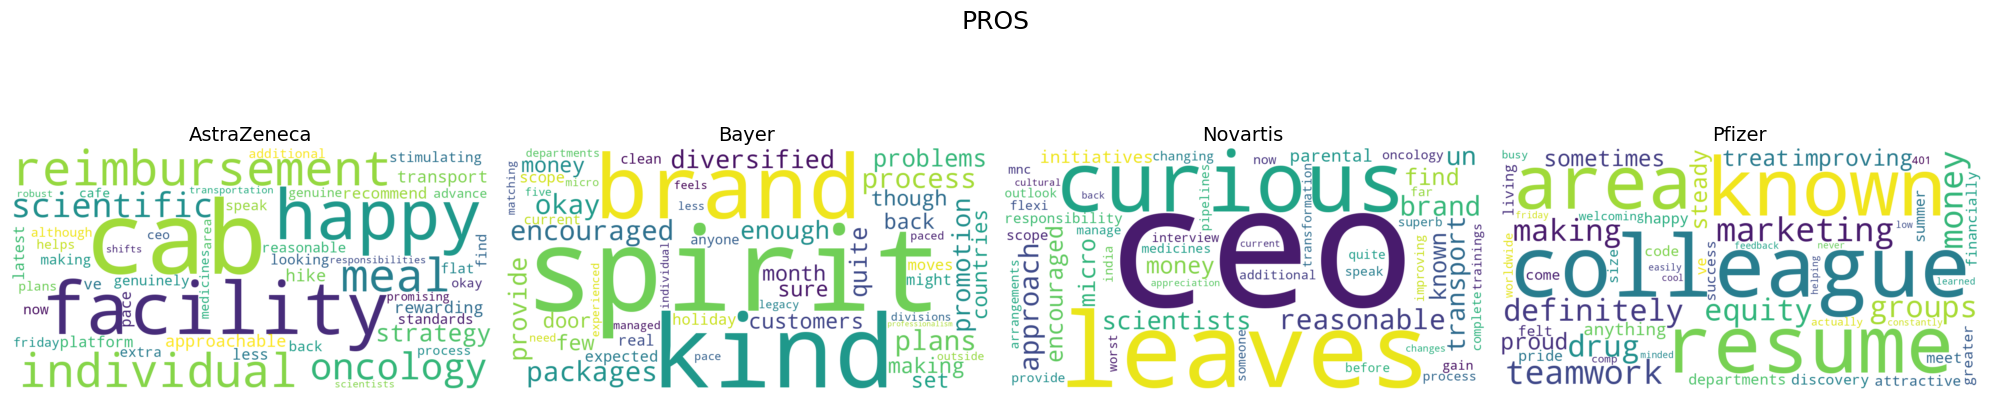

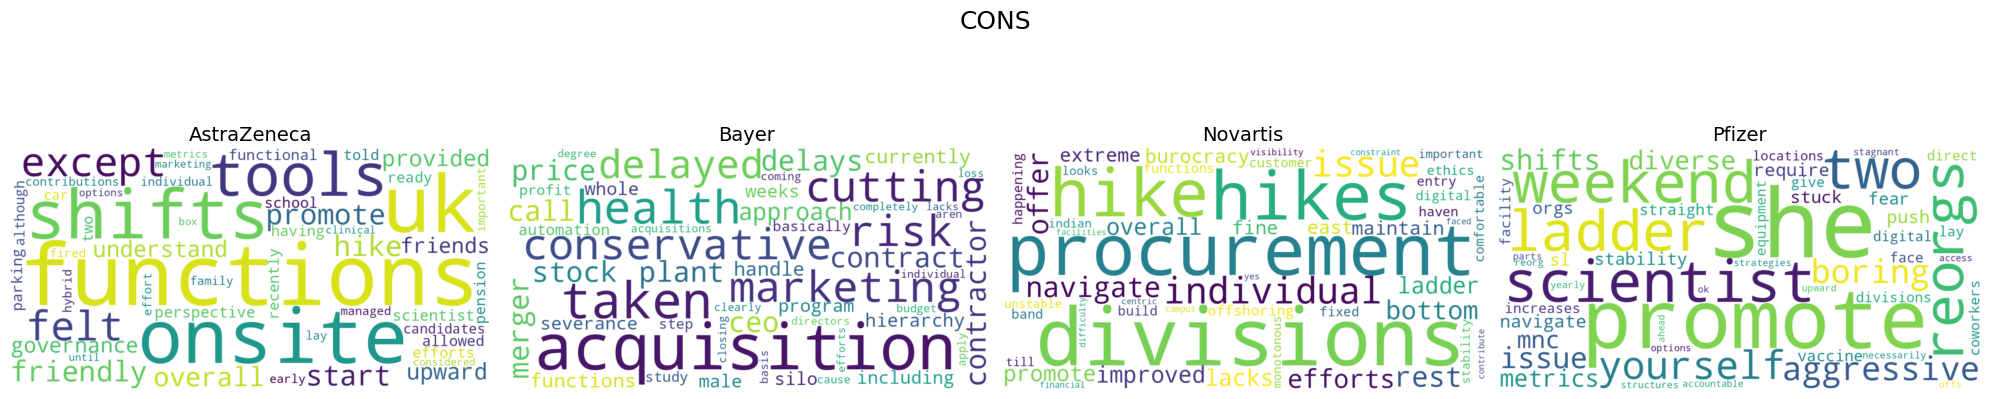

In [77]:
# WordClouds de PROS
generar_wordclouds_tfidf(df_clean, texto_col='pros')

# WordClouds de CONS
generar_wordclouds_tfidf(df_clean, texto_col='cons')

---
## 4. Comparación con peers



## **NOTA IMPORTANTE!!**

En un primer momento se asignaron manualmente topics con categorías, pero, como se comentó anteriormente, al trabajar en Google Colab tenemos un componente de aleatoriedad que no se puede controlar.

Por lo tanto se ha utilizado similitud del coseno para que asigne topics con categorías (éstas sí, definidas manualmente) de manera automática.

Las categorías de negocio en las que se pueden agrupar los topics son:


1: "Compensación y beneficios"

2 "Cultura, liderazgo y entorno laboral"

3: "Conciliación y flexibilidad"

4: "Entorno e instalaciones"

5: "Desarrollo profesional"

6: "Innovación, ciencia y propósito"

7: "Organización y estabilidad"


In [78]:
df_clean.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,...,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros,topic_cons,topic_pros_op,topic_cons_op,topic_pros_red,topic_cons_red
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,...,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",20,-1,16,-1,-1,-1
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,...,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,-1,-1,34,7,6,7
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,...,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,36,-1,-1,5,5,1
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,...,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,7,-1,7,-1,17,-1
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,...,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,5,5,5,7,-1,7


Aunque hemos ido acumulando columnas de topics para pros y para cons por cada modelo, en este momento nos vamos a quedar con las del modelo optimizado con topics reducidos.

In [79]:
df_op_red = df_clean.drop(columns=[
    "topic_pros",
    "topic_cons",
    "topic_pros_op",
    "topic_cons_op"
])

In [80]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity


# Categorías

categorias = {
    "Compensación y beneficios":
        "Salary compensation pay bonuses benefits rewards and employee compensation",

    "Cultura, liderazgo y entorno laboral":
        "Leadership management supervisors company culture teamwork collaboration communication and workplace relationships",

    "Conciliación y flexibilidad":
        "Work life balance flexibility remote work hybrid work working hours and personal wellbeing",

    "Entorno e instalaciones":
        "Physical work environment office facilities equipment resources workplace conditions and infrastructure",

    "Desarrollo profesional":
        "Career development promotion growth learning opportunities professional advancement and internal mobility",

    "Innovación, ciencia y propósito":
        "Innovation scientific research purpose meaningful work impact projects technology and innovation culture",

    "Organización y estabilidad":
        "Organization structure company stability restructuring processes workload planning and job security"
}

nombres = list(categorias.keys())
descripciones = list(categorias.values())


# Embedding

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Embeddings de categorías
emb_categorias = embedding_model.encode(descripciones)


# Excluir outliers (-1)
topics_validos_pros = topics_info_pros_red[
    topics_info_pros_red["Topic"] != -1
]["Topic"]

# Similitud del coseno
resultados_pros = []

for topic_id in topics_validos_pros:

    # Top palabras del topic
    palabras_pros = [
        palabra
        for palabra, _ in topic_model_pros_red.get_topic(topic_id)
    ]

    # Convertimos el topic en texto
    texto_topic_pros = " ".join(palabras_pros)

    # Embedding del topic
    emb_topic = embedding_model.encode([texto_topic_pros])

    # Similaridades
    sims = cosine_similarity(
        emb_topic,
        emb_categorias
    )[0]

    # Categoría ganadora
    idx_mejor = sims.argmax()

    categoria = nombres[idx_mejor]
    similitud = sims[idx_mejor]

    resultados_pros.append({
        "Topic": topic_id,
        "Palabras": texto_topic_pros,
        "Categoria": categoria,
        "Similitud": similitud
    })

# Resultado final
mapeo_topics_pros = pd.DataFrame(resultados_pros)

mapeo_topics_cons = mapeo_topics_pros.sort_values(
    by="Similitud",
    ascending=False
)

display(mapeo_topics_pros)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Topic,Palabras,Categoria,Similitud
0,0,company benefits good great salary pay opportu...,Compensación y beneficios,0.528008
1,1,culture work great good values people life bal...,"Cultura, liderazgo y entorno laboral",0.497760
2,2,team environment colleagues people friendly gr...,"Cultura, liderazgo y entorno laboral",0.367957
3,3,balance life work good benefits great employee...,Conciliación y flexibilidad,0.493085
4,4,place work great nice learn good location amin...,Entorno e instalaciones,0.370617
5,5,flexible hours working schedule flexibility re...,Conciliación y flexibilidad,0.794666
6,6,learning experience learn training opportuniti...,Desarrollo profesional,0.547253
7,7,pharma pharmaceutical oncology industry medici...,"Innovación, ciencia y propósito",0.199423
8,8,pipeline products basel promising great strong...,"Innovación, ciencia y propósito",0.205676
9,9,global international company travel opportunit...,Desarrollo profesional,0.432519


In [81]:
# Excluir outliers (-1)
topics_validos_cons = topics_info_cons_red[
    topics_info_cons_red["Topic"] != -1
]["Topic"]

# Similitud del coseno
resultados_cons = []

for topic_id in topics_validos_cons:

    # Top palabras del topic
    palabras_cons = [
        palabra
        for palabra, _ in topic_model_cons_red.get_topic(topic_id)
    ]

    # Convertimos el topic en texto
    texto_topic_cons = " ".join(palabras_cons)

    # Embedding del topic
    emb_topic = embedding_model.encode([texto_topic_cons])

    # Similaridades
    sims = cosine_similarity(
        emb_topic,
        emb_categorias
    )[0]

    # Categoría ganadora
    idx_mejor = sims.argmax()

    categoria = nombres[idx_mejor]
    similitud = sims[idx_mejor]

    resultados_cons.append({
        "Topic": topic_id,
        "Palabras": texto_topic_cons,
        "Categoria": categoria,
        "Similitud": similitud
    })

# Resultado final
mapeo_topics_cons = pd.DataFrame(resultados_cons)

mapeo_topics_cons = mapeo_topics_cons.sort_values(
    by="Similitud",
    ascending=False
)

display(mapeo_topics_cons)

,Topic,Palabras,Categoria,Similitud
5,5,career growth opportunities development limite...,Desarrollo profesional,0.638315
6,6,balance life work hours better demanding manag...,Conciliación y flexibilidad,0.620463
2,2,salary pay low benefits compensation compared ...,Compensación y beneficios,0.567130
1,1,management company leadership managers people ...,"Cultura, liderazgo y entorno laboral",0.516005
19,19,competitive environment etica office atmospher...,Entorno e instalaciones,0.500837
17,17,changes frequent change organizational organis...,Organización y estabilidad,0.469617
18,18,training learning skills learn opportunities l...,Desarrollo profesional,0.443403
7,7,promotion promotions promoted promote hard peo...,Desarrollo profesional,0.424283
16,16,projects project goals timelines skills given ...,"Innovación, ciencia y propósito",0.397774
8,8,hours long overtime work time working days sch...,Conciliación y flexibilidad,0.365436


In [82]:
dict_pros = dict(
    zip(
        mapeo_topics_pros["Topic"],
        mapeo_topics_pros["Categoria"]
    )
)

dict_cons = dict(
    zip(
        mapeo_topics_cons["Topic"],
        mapeo_topics_cons["Categoria"]
    )
)

In [83]:
df_op_red["categ_pros"] = [
    dict_pros.get(topic, "Otros")
    for topic in topics_pros_red
]
df_op_red.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros_red,topic_cons_red,categ_pros
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",-1,-1,Otros
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,6,7,Desarrollo profesional
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,more than 5y,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,5,1,Conciliación y flexibilidad
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,17,-1,Compensación y beneficios
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,more than 10y,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,-1,7,Otros


In [84]:
df_op_red["categ_cons"] = [
    dict_cons.get(topic, "Otros")
    for topic in topics_cons_red
]
df_op_red.head()

,firm,date_review,overall_rating,recommend,pros,cons,year,month,day,employee,tenure,sentiment_pros,sentiment_cons,pros_clean,cons_clean,topic_pros_red,topic_cons_red,categ_pros,categ_cons
0,AstraZeneca,2020-09-12,1,No,Company starting time good .. nothing present,"Management worest , personal feeling hikes , m...",2020,9,12,former,more than 3y,NEGATIVE,NEGATIVE,company starting time good .. nothing present,"management worest , personal feeling hikes , m...",-1,-1,Otros,Otros
1,AstraZeneca,2021-08-02,3,No,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,2021,8,2,former,more than 8y,POSITIVE,NEGATIVE,"development some pay and benefits good, share ...",not strong in terms of marketing campaigns for...,6,7,Desarrollo profesional,Desarrollo profesional
2,AstraZeneca,2022-02-16,1,No,None the worst to work for,Micro management Managers were not sales people,2022,2,16,former,more than 5y,NEGATIVE,NEGATIVE,none the worst to work for,micro management managers were not sales people,5,1,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral"
3,AstraZeneca,2021-01-17,4,Neutral,Good company. Good people. Good benefits,Same mid level management issues every large c...,2021,1,17,former,n/d,POSITIVE,NEGATIVE,good company. good people. good benefits,same mid level management issues every large c...,17,-1,Compensación y beneficios,Otros
4,AstraZeneca,2019-09-08,4,Yes,Decent benefits and pay. Nice employees.,Direction and vision is not always clear. Hard...,2019,9,8,current,more than 10y,POSITIVE,NEGATIVE,decent benefits and pay. nice employees.,direction and vision is not always clear. hard...,-1,7,Otros,Desarrollo profesional


In [85]:
(df_op_red["categ_pros"] == "Otros").sum()

np.int64(603)

In [86]:
(df_op_red["categ_cons"] == "Otros").sum()

np.int64(693)

Vamos a intentar incluir los outliers en alguna categoría

In [87]:
# Outliers de BERTopic
mask_outliers = pd.Series(topics_pros_red) == -1

for idx in df_op_red[mask_outliers].index:

    texto = str(df_op_red.loc[idx, "pros"])

    emb_texto = embedding_model.encode([texto])

    sims = cosine_similarity(
        emb_texto,
        emb_categorias
    )[0]

    categoria = nombres[sims.argmax()]

    df_op_red.loc[idx, "categ_pros"] = categoria

In [88]:
mask_outliers = pd.Series(topics_cons_red) == -1

for idx in df_op_red[mask_outliers].index:

    texto = str(df_op_red.loc[idx, "cons"])

    emb_texto = embedding_model.encode([texto])

    sims = cosine_similarity(
        emb_texto,
        emb_categorias
    )[0]

    categoria = nombres[sims.argmax()]

    df_op_red.loc[idx, "categ_cons"] = categoria

In [89]:
df_op_red.loc[
    pd.Series(topics_pros_red) == -1,
    ["pros", "categ_pros"]
].head(20)

,pros,categ_pros
0,Company starting time good .. nothing present,Organización y estabilidad
4,Decent benefits and pay. Nice employees.,Compensación y beneficios
11,"Good Collaboration, Teamwork, Flatter Org.","Cultura, liderazgo y entorno laboral"
14,- Bold and progressive sustainability ambition...,"Innovación, ciencia y propósito"
29,*Nice & understanding colleagues around. *Work...,Entorno e instalaciones
30,Latest technologies Great people Great Benefit...,Conciliación y flexibilidad
32,Good Shift Allowance Employee benefits All mov...,Conciliación y flexibilidad
34,"People, local leadership, autonomy, ability to...","Cultura, liderazgo y entorno laboral"
36,Good budget Supportive line manager Easy to us...,Entorno e instalaciones
47,exceptional mentors and investment into people...,Desarrollo profesional


In [90]:
df_op_red.loc[
    pd.Series(topics_cons_red) == -1,
    ["cons", "categ_cons"]
].head(20)

,cons,categ_cons
0,"Management worest , personal feeling hikes , m...",Organización y estabilidad
3,Same mid level management issues every large c...,Organización y estabilidad
7,Leadership is out of touch with day-to-day. Cl...,"Cultura, liderazgo y entorno laboral"
13,Hard to make a carrier if you are not in the g...,Desarrollo profesional
17,"too many layers, no remote jobs",Conciliación y flexibilidad
20,Mid management is not good. Politics at its peak.,"Cultura, liderazgo y entorno laboral"
29,*Micro-managed and political senior management...,Organización y estabilidad
30,Large Enterprise Too many architects The manag...,Organización y estabilidad
33,Almost impossible to get promoted without chan...,Desarrollo profesional
36,Limited budgets - Silo thinking - blame cultur...,"Innovación, ciencia y propósito"


In [91]:
(df_op_red["categ_pros"] == "Otros").sum()

np.int64(0)

In [92]:
(df_op_red["categ_cons"] == "Otros").sum()

np.int64(0)

Hemos conseguido incluir los outliers en las categorías

Para cada empresa calculo el % de reseñas cuyos pros caen en cada categoría, y lo mismo con los cons.


In [93]:
pct_firm_pros = (
    df_op_red.groupby("firm")["categ_pros"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
      .rename("pct_pros")
      .reset_index()
)


pros_pivot = pct_firm_pros.pivot(index="firm", columns="categ_pros", values="pct_pros").fillna(0)
pros_pivot



categ_pros,Compensación y beneficios,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral",Desarrollo profesional,Entorno e instalaciones,"Innovación, ciencia y propósito",Organización y estabilidad
firm,,,,,,,
AstraZeneca,26.0,29.3,15.0,21.6,1.4,5.3,1.4
Bayer,23.6,26.2,15.7,26.9,1.5,4.5,1.6
Novartis,23.1,29.3,19.5,21.5,1.1,4.6,0.9
Pfizer,26.2,22.7,16.3,27.4,1.7,4.8,0.9


In [94]:
pct_firm_cons = (
    df_op_red.groupby("firm")["categ_cons"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
      .rename("pct_cons")
      .reset_index()
)


cons_pivot = pct_firm_cons.pivot(index="firm", columns="categ_cons", values="pct_cons").fillna(0)
cons_pivot

categ_cons,Compensación y beneficios,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral",Desarrollo profesional,Entorno e instalaciones,"Innovación, ciencia y propósito",Organización y estabilidad
firm,,,,,,,
AstraZeneca,7.2,12.1,25.4,15.1,6.9,6.1,27.2
Bayer,8.7,9.7,23.5,13.4,5.0,3.6,36.1
Novartis,8.2,11.1,24.9,14.6,6.6,3.7,30.9
Pfizer,8.4,13.0,22.2,14.6,5.6,5.7,30.5


In [95]:
all_categories = sorted(set(pros_pivot.columns).union(cons_pivot.columns))

pros_aligned = pros_pivot.reindex(columns=all_categories, fill_value=0)
cons_aligned = cons_pivot.reindex(columns=all_categories, fill_value=0)


In [96]:
balance_net = pros_aligned - cons_aligned
balance_net = balance_net.round(2)

balance_net

categ_pros,Compensación y beneficios,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral",Desarrollo profesional,Entorno e instalaciones,"Innovación, ciencia y propósito",Organización y estabilidad
firm,,,,,,,
AstraZeneca,18.8,17.2,-10.4,6.5,-5.5,-0.8,-25.8
Bayer,14.9,16.5,-7.8,13.5,-3.5,0.9,-34.5
Novartis,14.9,18.2,-5.4,6.9,-5.5,0.9,-30.0
Pfizer,17.8,9.7,-5.9,12.8,-3.9,-0.9,-29.6


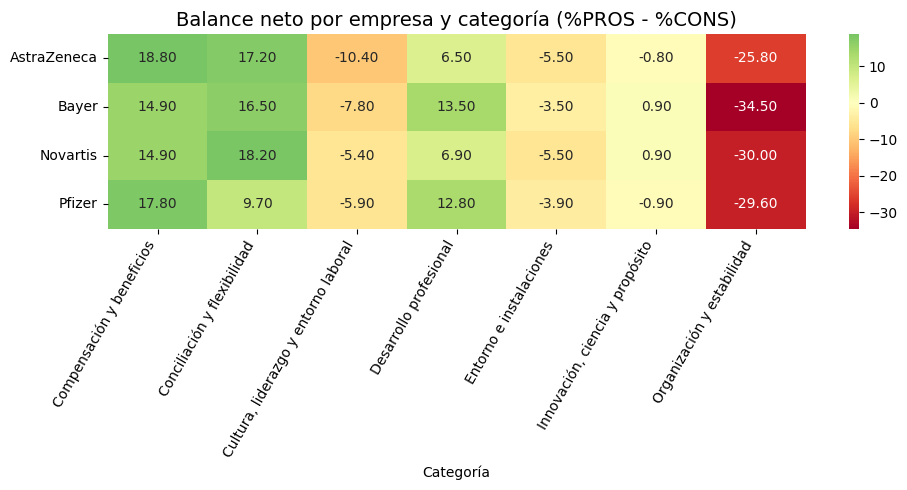

In [97]:
plt.figure(figsize=(10, 5))
sns.heatmap(
    balance_net,
    annot=True,
    cmap="RdYlGn",
    center=0,
    fmt=".2f"
)

plt.title("Balance neto por empresa y categoría (%PROS - %CONS)", fontsize=14)
plt.xlabel("Categoría")
plt.ylabel("")
plt.yticks(rotation=0)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


La categoría con peor balance de resultados es Organización y estabilidad para las cuatro empresas estudiadas, especialmente para la empresa objetivo. En ésta también se observan más cons que pros en Cultura, liderazgo y entono laboral y en Entono e insatalaciones. Por otro lado, Conciliación y flexibilidad, Compensación y beneficios y Desarrollo profesional son los que acumulan más reseñas pros.

---
## 5. Empleados actuales vs. antiguos

Comparo las cateogrías de pros y cons de los empleados actuales vs empleados antiguos. Esto nos puede dar una indicacón de qué aspectos favorecen la retención y cuales el abandono.


In [98]:
df_bayer = df_op_red[df["firm"] == "Bayer"]

pct_cons_bayer = (
    df_bayer.groupby("employee")["categ_cons"]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
            .rename("pct_cons")
            .reset_index()
)

pct_cons_bayer


,employee,categ_cons,pct_cons
0,current,Organización y estabilidad,36.20
1,current,"Cultura, liderazgo y entorno laboral",22.15
2,current,Desarrollo profesional,14.55
3,current,Compensación y beneficios,9.75
4,current,Conciliación y flexibilidad,9.59
5,current,Entorno e instalaciones,4.63
6,current,"Innovación, ciencia y propósito",3.14
7,former,Organización y estabilidad,35.95
8,former,"Cultura, liderazgo y entorno laboral",25.57
9,former,Desarrollo profesional,11.65


In [99]:
cons_bayer_pivot = pct_cons_bayer.pivot(
    index="employee",
    columns="categ_cons",
    values="pct_cons"
).fillna(0)

cons_bayer_pivot


categ_cons,Compensación y beneficios,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral",Desarrollo profesional,Entorno e instalaciones,"Innovación, ciencia y propósito",Organización y estabilidad
employee,,,,,,,
current,9.75,9.59,22.15,14.55,4.63,3.14,36.20
former,7.09,9.87,25.57,11.65,5.57,4.30,35.95


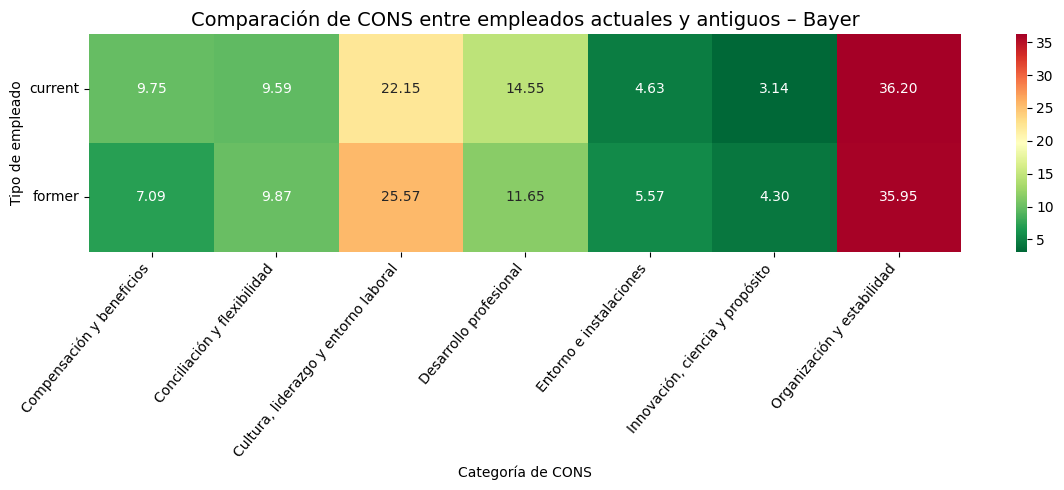

In [100]:
plt.figure(figsize=(12, 5))
sns.heatmap(
    cons_bayer_pivot,
    annot=True,
    cmap="RdYlGn_r",   # rojo = peor, verde = mejor
    fmt=".2f"
)

plt.title("Comparación de CONS entre empleados actuales y antiguos – Bayer", fontsize=14)
plt.xlabel("Categoría de CONS")
plt.ylabel("Tipo de empleado")
plt.yticks(rotation=0)
plt.xticks(rotation=50, ha="right")
plt.tight_layout()
plt.show()


La categoría mayoritaria de cons es Organización y estabilidad seguida de Desarrollo Profesional, con resultados similares para empleados antiguos o actuales

In [101]:
pct_pros_bayer = (
    df_bayer.groupby("employee")["categ_pros"]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
            .rename("pct_cons")
            .reset_index()
)

pct_pros_bayer

,employee,categ_pros,pct_cons
0,current,Conciliación y flexibilidad,29.09
1,current,Desarrollo profesional,25.95
2,current,Compensación y beneficios,23.31
3,current,"Cultura, liderazgo y entorno laboral",15.04
4,current,"Innovación, ciencia y propósito",3.97
5,current,Entorno e instalaciones,1.49
6,current,Organización y estabilidad,1.16
7,former,Desarrollo profesional,28.35
8,former,Compensación y beneficios,24.05
9,former,Conciliación y flexibilidad,21.77


In [102]:
pros_bayer_pivot = pct_pros_bayer.pivot(
    index="employee",
    columns="categ_pros",
    values="pct_cons"
).fillna(0)

pros_bayer_pivot

categ_pros,Compensación y beneficios,Conciliación y flexibilidad,"Cultura, liderazgo y entorno laboral",Desarrollo profesional,Entorno e instalaciones,"Innovación, ciencia y propósito",Organización y estabilidad
employee,,,,,,,
current,23.31,29.09,15.04,25.95,1.49,3.97,1.16
former,24.05,21.77,16.71,28.35,1.52,5.32,2.28


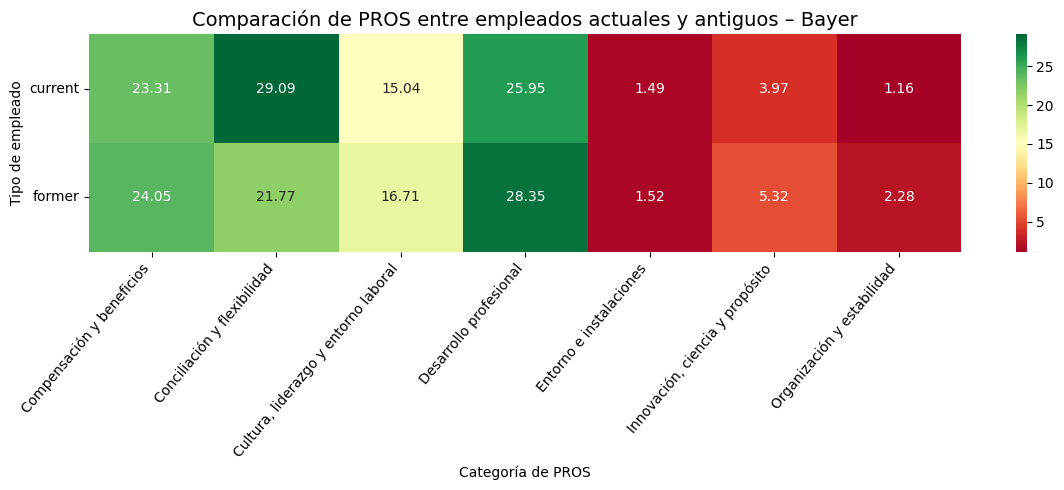

In [103]:
plt.figure(figsize=(12, 5))
sns.heatmap(
    pros_bayer_pivot,
    annot=True,
    cmap="RdYlGn",   # rojo = peor, verde = mejor
    fmt=".2f"
)

plt.title("Comparación de PROS entre empleados actuales y antiguos – Bayer", fontsize=14)
plt.xlabel("Categoría de PROS")
plt.ylabel("Tipo de empleado")
plt.yticks(rotation=0)
plt.xticks(rotation=50, ha="right")
plt.tight_layout()
plt.show()

Las categoría mayoritarias de pros son Conciliación y flexibilidad, Desarrollo Profesional y Compensación y Beneficios, con resultados superiores para los empleados actuales en Conciliación y flexibilidad

# Matriz de priorización

Se construye una matriz de priorización donde el peso (eje X) es el % de cons en nuestra empresa objetivo, el gap (eje y) es la diferencia entre % de cons en la empresa objetivo y %cons en la media de los peers. Para obtener más informaciòn en un sólo gráfico el tamaño de cada punto varía en función del % de cons en esa categoría para los peers.

In [104]:
target= "Bayer"

# % de categorías Cons por empresa
tabla = pd.crosstab(
df_op_red["firm"],
df_op_red["categ_cons"],
normalize="index"
) * 100

# Media de peers
media_peers = tabla.drop(index=target).mean()

# Peso (% de Cons de Bayer en cada categoría)
peso = tabla.loc[target]

# Gap frente a peers
gap = peso - media_peers


# DataFrame final para la matriz
matriz_priorizacion = pd.DataFrame({
    "Categoria": peso.index,
    "Peso": peso.values,
    "Gap": gap.values,
    "Peers": media_peers.values
})

# Ordenar por peso
matriz_priorizacion = matriz_priorizacion.sort_values(
by="Peso",
ascending=False
)

In [105]:
matriz_priorizacion.columns

Index(['Categoria', 'Peso', 'Gap', 'Peers'], dtype='object')

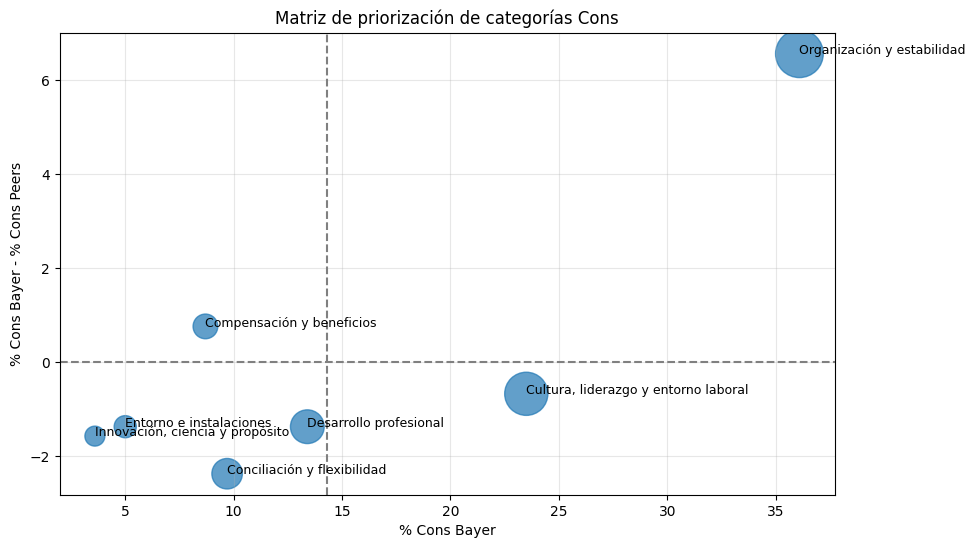

In [106]:
plt.figure(figsize=(10, 6))

plt.scatter(
    matriz_priorizacion["Peso"],
    matriz_priorizacion["Gap"],
    s=matriz_priorizacion["Peers"] * 40,
    alpha=0.7
)

for _, row in matriz_priorizacion.iterrows():
    plt.annotate(
        row["Categoria"],
        (row["Peso"], row["Gap"]),
        fontsize=9
    )

# Líneas de referencia
plt.axhline(0, color="grey", linestyle="--")

plt.axvline(
    matriz_priorizacion["Peso"].mean(),
    color="grey",
    linestyle="--"
)

plt.xlabel("% Cons Bayer")
plt.ylabel("% Cons Bayer - % Cons Peers")
plt.title("Matriz de priorización de categorías Cons")

plt.grid(alpha=0.3)

plt.show()

La categoría con más peso en la empresa objetivo y con más diferencia en sentido negativo (es decir, más % Cons que los peers) es Organización y estabilidad. El mayor tamaño del punto nos indica que son categorias con un elevado porcentaje de Cons también en los peers. En Compensación y beneficios también estamos ligeramente peor que los peers pero con menos peso en el % de reseñas

---
## 6. Conclusiones y recomendaciones para RRHH


La categoría mayoritaria de cons es Organización y estabilidad seguida de Desarrollo Profesional, con resultados similares para empleados antiguos o actuales. Esta categoría es en la que peor estamos en todos los aspectos, tanto por el % de reseñas cons como por la diferencia con los peers como se aprecia en la matriz de priorización

Por otro lado se observa que los empleados valoran más positivamente los temas de Desarrollo profesional, Compensación y beneficios y Conciliación y flexibilidad, la última categoría especialmente por los empleados actuales, lo que habría que tener en cuenta para retener o atraer talento

Ya que en cuanto a Desarrollo Profesional hay gran cantidad de reseñas tanto en cons como en pros, sería interesante analizar más en profundidad esta categoría para ver los puntos fuertes y débiles, aunque es verdad que la matriz de priorización nos dice que en este aspecto estamos mejor que nuestros peers.



